<center>
<h1><b>TP3 : Prompt Engineering</b></h1>
<h2><b>Tâches de classification : analyse de sentiment</b></h2>
</center>

# Objectifs

- Présenter les LLM comme un outil efficace pour traiter des problèmes de classification.
- Illustrer le prompt engineering pour l'analyse de sentiment.
- Construire et évaluer des prompts sur une tâche de classification.

Le notebook suit les quatre étapes de l'énoncé (`TP3 prompt Sentimental analysis.pdf`) :

1. définir les objectifs et les métriques ;
2. constituer les données (exemples et exemples de référence) ;
3. élaborer trois prompts : zero-shot, few-shot et Chain-of-Thought ;
4. évaluer les prompts avec le score micro-F1, sur plusieurs tirages d'exemples.

Les réponses rédigées se trouvent dans [`REPONSES.md`](REPONSES.md).

**Adaptations par rapport à l'énoncé** (détaillées dans `REPONSES.md`) :

- le modèle est `gemini-3.5-flash-lite` via l'API gratuite de Google (`ChatGoogleGenerativeAI`) au lieu de `gpt-5.2` (API payante) ;
- les données viennent du fichier fourni `dataset_imdb.zip` au lieu de `load_dataset("imdb")` ;
- les erreurs du code de l'énoncé sont corrigées (`user_message_template` et `import json` manquants, prompt CoT jamais évalué dans la boucle).

# 0. Environnement

Projet géré avec `uv` (`pyproject.toml`). La clé d'API est lue depuis un fichier `.env` (`GOOGLE_API_KEY=...`) qui n'est pas versionné.

In [1]:
import json
import session_info
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.rate_limiters import InMemoryRateLimiter

plt.rcParams["figure.dpi"] = 110

In [2]:
session_info.show()

In [3]:
load_dotenv(override=True)

True

# Étape 1 : Objectifs et métriques

On attribue à chaque avis l'une des deux étiquettes `positive` ou `negative`. La performance d'un prompt est mesurée par :

- le **taux d'exactitude** (accuracy) : proportion de prédictions égales à l'étiquette de référence ;
- le **score micro-F1** : TP, FP et FN sont additionnés sur **toutes les classes** avant de calculer la précision, le rappel et le F1.

On vérifie avec `scikit-learn` l'exemple de matrice de confusion de l'énoncé (lignes = prédit, colonnes = réel) :

| Prédit \ Réel | Positif | Négatif |
|---|---|---|
| **Positif** | 50 | 10 |
| **Négatif** | 5 | 100 |

In [4]:
y_true = ["positive"] * 50 + ["negative"] * 10 + ["positive"] * 5 + ["negative"] * 100
y_pred = ["positive"] * 50 + ["positive"] * 10 + ["negative"] * 5 + ["negative"] * 100

print(f"Accuracy                     : {accuracy_score(y_true, y_pred):.3f}")
print(f"F1 de la classe positive     : {f1_score(y_true, y_pred, pos_label='positive', average='binary'):.3f}")
print(f"F1 de la classe negative     : {f1_score(y_true, y_pred, pos_label='negative', average='binary'):.3f}")
print(f"Micro-F1                     : {f1_score(y_true, y_pred, average='micro'):.3f}")
print(f"Macro-F1                     : {f1_score(y_true, y_pred, average='macro'):.3f}")

Accuracy                     : 0.909
F1 de la classe positive     : 0.870
F1 de la classe negative     : 0.930
Micro-F1                     : 0.909
Macro-F1                     : 0.900


La valeur 0,870 de l'énoncé est le **F1 de la classe positive** seule. Le vrai micro-F1 additionne les deux classes :
TP = 50 + 100 = 150, FP = 10 + 5 = 15, FN = 5 + 10 = 15, d'où précision = rappel = F1 = 150 / 165 = **0,909**.
Pour une classification à une seule étiquette par exemple, le micro-F1 est donc toujours égal à l'accuracy.

# Étape 2 : Constitution des données

## 2.1 Chargement du jeu de données IMDB

Le fichier fourni `dataset_imdb.zip` contient `IMDB Dataset.csv` : 50 000 avis IMDB (les parties `train` et `test` du jeu Hugging Face réunies), avec les colonnes `review` et `sentiment`. `pandas` lit directement le zip.

In [5]:
df = pd.read_csv("dataset_imdb.zip")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


In [6]:
df.duplicated().sum()

np.int64(418)

On renomme `review` en `text` pour retrouver le format de l'énoncé, on supprime les doublons (sinon un même avis pourrait se retrouver à la fois dans les exemples et dans les exemples de référence) et on recrée la colonne numérique `label` (1 = positif, 0 = négatif).

In [7]:
df = df.rename(columns={"review": "text"}).drop_duplicates().reset_index(drop=True)
df["label"] = np.where(df.sentiment == "positive", 1, 0)
df = df[["text", "label", "sentiment"]]
df.sample(6, random_state=0)

,text,label,sentiment
166,Originally I was a Tenacious D fan of their fi...,1,positive
27909,This first-rate western tale of the gold rush ...,1,positive
35746,One of the all-time great science fiction work...,1,positive
1872,Mickey Rourke ( who was once a famous movie st...,0,negative
12703,this is the worst movie ive ever seen. And i h...,0,negative
16108,Drivel. Utter junk. The writers must not have ...,0,negative


In [8]:
df.sentiment.value_counts()

sentiment
positive    24884
negative    24698
Name: count, dtype: int64

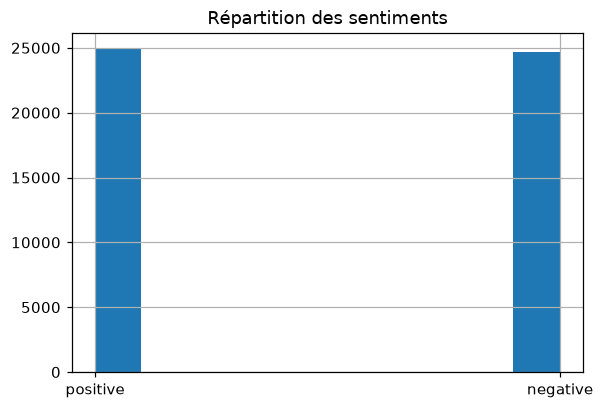

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
df.sentiment.hist(ax=ax)
ax.set_title("Répartition des sentiments")
fig.savefig("figures/01_equilibre_classes.png", bbox_inches="tight")
plt.show()

Le jeu de données est équilibré (environ 50 % de chaque classe), ce qui justifie l'usage du micro-F1.

## 2.2 Exemples et exemples de référence (gold examples)

80 % des avis forment le réservoir d'**exemples** dans lequel on tire les exemples few-shot, 20 % forment le réservoir d'**exemples de référence** qui servent uniquement à évaluer les prompts.

In [10]:
examples_df, gold_examples_df = train_test_split(df, test_size=0.2, random_state=42)
(examples_df.shape, gold_examples_df.shape)

((39665, 3), (9917, 3))

Pour garder des temps d'exécution raisonnables, on retient 20 exemples de référence, tirés avec `random_state=42` pour qu'ils soient identiques à chaque exécution. Ils sont enregistrés en JSON pour être réutilisés.

In [11]:
columns = ["text", "sentiment"]
gold_examples = (
    gold_examples_df.loc[:, columns]
    .sample(20, random_state=42)
    .to_json(orient="records")
)

with open("data/gold_examples.json", "w", encoding="utf-8") as f:
    json.dump(json.loads(gold_examples), f, ensure_ascii=False, indent=2)

json.loads(gold_examples)[0]

{'text': 'Ernst Lubitsch\'s contribution to the American cinema is enormous. His legacy is an outstanding group of movies that will live forever, as is the case with "The Shop Around the Corner". This film has been remade into other less distinguished movies and a musical play, without the charm or elegance of Mr. Lubitsch\'s own, and definite version.<br /><br />Margaret Sullavan and James Stewart worked in several films together. Their characters in this movie stand out as an example of how to be in a movie without almost appearing to be acting at all. Both stars are delightful as the pen pals that don\'t know of one another, but who fate had them working together in the same shop in Budapest.<br /><br />The reason why these classic films worked so well is the amazing supporting casts the studios put together in picture after picture. In here, we have the wonderful Frank Morgan, playing the owner of the shop. Also, we see Joseph Schildkraut, Felix Bressart, William Tracy and Charles 

In [12]:
pd.read_json("data/gold_examples.json").sentiment.value_counts()

sentiment
negative    12
positive     8
Name: count, dtype: int64

# Étape 3 : Élaboration des prompts

Chaque avis est envoyé au modèle entre triples backticks. L'énoncé utilise `user_message_template` sans le définir ; on le définit ici.

In [13]:
user_message_template = """```{movie_review}```"""

## Prompt 1 : Zero-shot

Uniquement des instructions, sans aucun exemple.

In [14]:
zero_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.
"""

zero_shot_prompt = [{"role": "system", "content": zero_shot_system_message}]

## Prompt 2 : Few-shot

Le message système est identique au zero-shot. On l'enrichit avec des exemples tirés du réservoir d'exemples.

In [15]:
few_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.
"""

In [16]:
positive_reviews = (examples_df.sentiment == "positive")
negative_reviews = (examples_df.sentiment == "negative")
(positive_reviews.shape, negative_reviews.shape)

((39665,), (39665,))

Ces deux formes sont celles de **masques booléens** (une valeur `True`/`False` par ligne de `examples_df`), pas le nombre d'avis de chaque classe. Le nombre d'avis s'obtient avec `.sum()` :

In [17]:
(positive_reviews.sum(), negative_reviews.sum())

(np.int64(19906), np.int64(19759))

Les tirages d'exemples utilisent le générateur aléatoire global de NumPy ; on fixe sa graine pour que le notebook soit reproductible.

In [18]:
np.random.seed(42)

columns = ["text", "sentiment"]
positive_examples = examples_df.loc[positive_reviews, columns].sample(4)
negative_examples = examples_df.loc[negative_reviews, columns].sample(4)
positive_examples

,text,sentiment
32659,"While the camerawork was certainly ""funky"" - p...",positive
28041,I don't understand your objections to this mov...,positive
9316,This is one of the best episodes from the enti...,positive
2773,Documentary starts in 1986 in NYC where black ...,positive


In [19]:
negative_examples

,text,sentiment
3740,"I'm sorry, perhaps this is part of the wave of...",negative
2909,"A mean spirited, repulsive horror film about 3...",negative
37671,This movie was bad on so many levels. The writ...,negative
32824,"In my opinion, this movie is not good. I hardl...",negative


Tirer des exemples au hasard ne suffit pas : les exemples d'un prompt sont sujets au **biais de l'étiquette majoritaire** (le modèle reproduit l'étiquette la plus fréquente dans les exemples) et au **biais de récence** (les derniers exemples pèsent davantage). La fonction `create_examples` tire autant d'exemples de chaque classe puis les mélange.

In [20]:
def create_examples(dataset, n=4):
    positive_reviews = (dataset.sentiment == "positive")
    negative_reviews = (dataset.sentiment == "negative")
    columns_to_select = ["text", "sentiment"]
    positive_examples = dataset.loc[positive_reviews, columns_to_select].sample(n)
    negative_examples = dataset.loc[negative_reviews, columns_to_select].sample(n)
    examples = pd.concat([positive_examples, negative_examples])
    randomized_examples = examples.sample(2 * n, replace=False)
    return randomized_examples.to_json(orient="records")

In [21]:
examples = create_examples(examples_df, 2)
json.loads(examples)

[{'text': 'Not everyone likes this movie. It is still one of the best "you have to be thinking" movies about Satanism ever made. The fact that it doesn\'t have MTV-era jump cuts or gore every seven minutes is irrelevant. Also, speaking as someone who actually KNOWS Satanists, the (spoiler warning!) portion of the film where the Brotherhood exchange their old bodies for those of preadolescent children, it has some genuinely scary scenes. The section where (second spoiler alert) Strother Martin orchestrates the changeover is almost hyper-real in that it uses very few special effects, a hallmark of this film. McEveety was seldom given a big budget but was often effective. It worked in this case, too.',
  'sentiment': 'positive'},
 {'text': "This is the worst italian movie ever, quite possibly the worst movie of all time! Joe D'Amato is of course no cinematic genius but many of his movies are interesting and watchable. Unfortunatly this is not one of them. Its cheesy and boring....waaaaay 

`create_prompt` transforme les exemples en un historique de conversation : chaque avis devient un message `user` et son étiquette la réponse `assistant` correspondante. Le modèle voit ainsi plusieurs réponses correctes au format attendu avant l'avis à classer.

In [22]:
def create_prompt(system_message, examples, user_message_template):
    few_shot_prompt = [{"role": "system", "content": system_message}]
    for example in json.loads(examples):
        example_review = example["text"]
        example_sentiment = example["sentiment"]
        few_shot_prompt.append(
            {
                "role": "user",
                "content": user_message_template.format(movie_review=example_review)
            }
        )
        few_shot_prompt.append(
            {"role": "assistant", "content": f"{example_sentiment}"}
        )
    return few_shot_prompt

In [23]:
few_shot_prompt = create_prompt(few_shot_system_message, examples, user_message_template)
few_shot_prompt

[{'role': 'system',
  'content': "\nClassify the sentiment of movie reviews presented in the input as 'positive' or 'negative'\nMovie reviews will be delimited by triple backticks in the input.\nAnswer only 'positive' or 'negative'\nDo not explain your answer.\n"},
 {'role': 'user',
  'content': '```Not everyone likes this movie. It is still one of the best "you have to be thinking" movies about Satanism ever made. The fact that it doesn\'t have MTV-era jump cuts or gore every seven minutes is irrelevant. Also, speaking as someone who actually KNOWS Satanists, the (spoiler warning!) portion of the film where the Brotherhood exchange their old bodies for those of preadolescent children, it has some genuinely scary scenes. The section where (second spoiler alert) Strother Martin orchestrates the changeover is almost hyper-real in that it uses very few special effects, a hallmark of this film. McEveety was seldom given a big budget but was often effective. It worked in this case, too.```'

## Prompt 3 : Chain-of-Thought

Mêmes exemples que le few-shot ; seul le message système change, avec des instructions de raisonnement étape par étape.

In [24]:
cot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks ``` in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.

Instructions:
1. Carefully read the text of the review and think through the options for sentiment provided
2. Consider the overall sentiment of the review and estimate the probability of the review being positive

To reiterate, your answer should strictly only contain the label: positive or negative
"""

cot_few_shot_prompt = create_prompt(cot_system_message, examples, user_message_template)

In [25]:
print(cot_few_shot_prompt[0]["content"])
print(f"{len(cot_few_shot_prompt)} messages : 1 message système + {len(cot_few_shot_prompt) - 1} messages d'exemples")


Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks ``` in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.

Instructions:
1. Carefully read the text of the review and think through the options for sentiment provided
2. Consider the overall sentiment of the review and estimate the probability of the review being positive

To reiterate, your answer should strictly only contain the label: positive or negative

9 messages : 1 message système + 8 messages d'exemples


# Étape 4 : Évaluation des prompts

## 4.1 Le modèle

- `gemini-3.5-flash-lite` remplace `gpt-5.2` (API gratuite).
- `thinking_level="minimal"` : les modèles Gemini 3 « réfléchissent » par défaut avant de répondre, ce qui rendait un appel très lent (plus d'une minute) et renvoyait `.content` sous forme de liste de blocs. Au niveau minimal, un appel prend environ une seconde. Le prompt CoT de l'énoncé ne repose que sur des instructions, les trois prompts sont donc évalués dans les mêmes conditions.
- Pas de `temperature=0` : Gemini 3 impose ses paramètres d'échantillonnage et ignore la température. Les réponses ne sont donc pas garanties identiques d'une exécution à l'autre.
- Un `InMemoryRateLimiter` espace les requêtes pour rester sous les limites de l'offre gratuite, et `max_retries` relance automatiquement une requête refusée.

In [26]:
rate_limiter = InMemoryRateLimiter(requests_per_second=0.2)
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    thinking_level="minimal",
    rate_limiter=rate_limiter,
    max_retries=6,
)

## 4.2 Fonction d'évaluation

Reprise de l'énoncé, avec une seule modification : la réponse est lue avec `response.text` (toujours une chaîne) au lieu de `response.content`, qui peut être une liste de blocs avec Gemini 3 et ferait échouer `.strip().lower()`.

In [27]:
def evaluate_prompt(prompt, gold_examples, user_message_template, model):
    model_predictions, ground_truths = [], []
    for example in json.loads(gold_examples):
        gold_input = example["text"]
        user_input = [
            {
                "role": "user",
                "content": user_message_template.format(movie_review=gold_input)
            }
        ]
        try:
            response = model.invoke(prompt + user_input)
            response_content = response.text if hasattr(response, "text") else response
            if "negative" in response_content.strip().lower():
                prediction = "negative"
            elif "positive" in response_content.strip().lower():
                prediction = "positive"
            else:
                prediction = "unknown"
            model_predictions.append(prediction)
            ground_truths.append(example["sentiment"])
        except Exception as e:
            print(e)
            continue
    micro_f1_score = f1_score(ground_truths, model_predictions, average="micro")
    return micro_f1_score

Une évaluation complète représente plusieurs centaines d'appels. Pour ne pas tout perdre si l'exécution est interrompue, chaque résultat est enregistré dans `data/evaluations_cache.json` dès qu'il est calculé, et une nouvelle exécution réutilise les résultats déjà présents. Supprimer ce fichier relance tous les appels.

In [28]:
CACHE_PATH = "data/evaluations_cache.json"
try:
    with open(CACHE_PATH, encoding="utf-8") as f:
        cache = json.load(f)
except FileNotFoundError:
    cache = {}


def cached(key, compute):
    if key not in cache:
        cache[key] = compute()
        with open(CACHE_PATH, "w", encoding="utf-8") as f:
            json.dump(cache, f, indent=2)
    return cache[key]

## 4.3 Évaluation de chaque prompt (un seul tirage d'exemples)

In [29]:
zero_shot_f1 = cached("zero_shot", lambda: evaluate_prompt(zero_shot_prompt, gold_examples, user_message_template, llm))
zero_shot_f1

1.0

In [30]:
few_shot_f1 = cached("few_shot", lambda: evaluate_prompt(few_shot_prompt, gold_examples, user_message_template, llm))
few_shot_f1

1.0

In [31]:
cot_f1 = cached("cot", lambda: evaluate_prompt(cot_few_shot_prompt, gold_examples, user_message_template, llm))
cot_f1

1.0

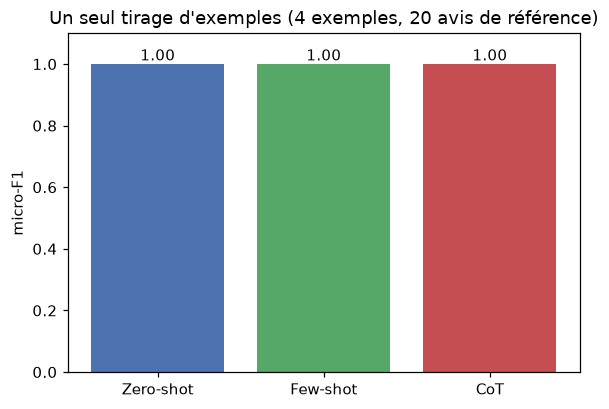

In [32]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Zero-shot", "Few-shot", "CoT"], [zero_shot_f1, few_shot_f1, cot_f1], color=["#4C72B0", "#55A868", "#C44E52"])
ax.bar_label(bars, fmt="%.2f")
ax.set_ylim(0, 1.1)
ax.set_ylabel("micro-F1")
ax.set_title("Un seul tirage d'exemples (4 exemples, 20 avis de référence)")
fig.savefig("figures/02_scores_tirage_unique.png", bbox_inches="tight")
plt.show()

## 4.4 Évaluations répétées

Le few-shot et le CoT dépendent des exemples tirés. On répète l'évaluation plusieurs fois, avec à chaque fois un nouveau tirage de 8 exemples (4 positifs, 4 négatifs), pour estimer la moyenne et l'écart-type du micro-F1.

**Nombre de tirages** : l'énoncé en fait 10. L'offre gratuite de l'API Gemini est limitée à 500 requêtes par jour pour ce modèle, et chaque tirage coûte 40 appels (2 prompts × 20 avis). Le quota a été atteint après 4 tirages ; comme les 8 évaluations obtenues donnent toutes un micro-F1 de 1,0, on s'arrête à 4 tirages.

**Correction de l'énoncé** : dans la boucle de l'énoncé, le prompt CoT n'est jamais construit ni évalué (la liste `cot_few_shot_performance` reçoit le score du few-shot). Ici, à chaque tour, les deux prompts sont construits avec les mêmes exemples et évalués tous les deux.

In [33]:
num_eval_runs = 4
few_shot_performance, cot_few_shot_performance = [], []

for run in tqdm(range(num_eval_runs)):
    examples = create_examples(examples_df)
    few_shot_prompt = create_prompt(few_shot_system_message, examples, user_message_template)
    cot_few_shot_prompt = create_prompt(cot_system_message, examples, user_message_template)
    few_shot_performance.append(cached(f"run_{run}_few_shot", lambda: evaluate_prompt(few_shot_prompt, gold_examples, user_message_template, llm)))
    cot_few_shot_performance.append(cached(f"run_{run}_cot", lambda: evaluate_prompt(cot_few_shot_prompt, gold_examples, user_message_template, llm)))

  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00, 111.67it/s]

In [34]:
for name, perf in [("Few-shot", few_shot_performance), ("CoT", cot_few_shot_performance)]:
    mean_val = np.array(perf).mean()
    std_val = np.array(perf).std()
    print(f"{name:9}: f1_score Moyen = {mean_val:.3f}, Standard Deviation = {std_val:.3f}")

Few-shot : f1_score Moyen = 1.000, Standard Deviation = 0.000
CoT      : f1_score Moyen = 1.000, Standard Deviation = 0.000


In [35]:
runs_df = pd.DataFrame({
    "run": range(1, num_eval_runs + 1),
    "few_shot": few_shot_performance,
    "cot": cot_few_shot_performance,
})
runs_df

,run,few_shot,cot
0,1,1.0,1.0
1,2,1.0,1.0
2,3,1.0,1.0
3,4,1.0,1.0


In [36]:
summary = pd.DataFrame({
    "prompt": ["Zero-shot", "Few-shot", "CoT"],
    "tirages": [1, num_eval_runs, num_eval_runs],
    "micro_f1_moyen": [zero_shot_f1, np.mean(few_shot_performance), np.mean(cot_few_shot_performance)],
    "ecart_type": [0.0, np.std(few_shot_performance), np.std(cot_few_shot_performance)],
    "min": [zero_shot_f1, np.min(few_shot_performance), np.min(cot_few_shot_performance)],
    "max": [zero_shot_f1, np.max(few_shot_performance), np.max(cot_few_shot_performance)],
}).round(3)
summary

,prompt,tirages,micro_f1_moyen,ecart_type,min,max
0,Zero-shot,1,1.0,0.0,1.0,1.0
1,Few-shot,4,1.0,0.0,1.0,1.0
2,CoT,4,1.0,0.0,1.0,1.0


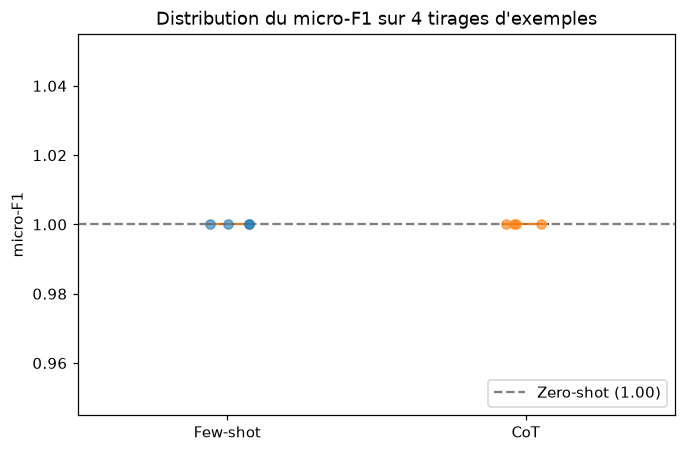

In [37]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot([few_shot_performance, cot_few_shot_performance], tick_labels=["Few-shot", "CoT"])
for i, perf in enumerate([few_shot_performance, cot_few_shot_performance], start=1):
    jitter = np.random.default_rng(i).uniform(-0.08, 0.08, len(perf))
    ax.scatter(np.full(len(perf), i) + jitter, perf, alpha=0.6, zorder=3)
ax.axhline(zero_shot_f1, color="gray", linestyle="--", label=f"Zero-shot ({zero_shot_f1:.2f})")
ax.set_ylabel("micro-F1")
ax.set_title(f"Distribution du micro-F1 sur {num_eval_runs} tirages d'exemples")
ax.legend(loc="lower right")
fig.savefig("figures/03_distribution_scores_runs.png", bbox_inches="tight")
plt.show()

In [38]:
results = {
    "model": "gemini-3.5-flash-lite",
    "num_gold_examples": len(json.loads(gold_examples)),
    "single_draw": {"zero_shot": zero_shot_f1, "few_shot": few_shot_f1, "cot": cot_f1},
    "repeated_runs": {"few_shot": few_shot_performance, "cot": cot_few_shot_performance},
}
with open("data/resultats.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

---
**Fin du notebook.** Les réponses rédigées, appuyées sur les résultats ci-dessus, sont dans [`REPONSES.md`](REPONSES.md).